# 03: contrastive edge loss inside the official LEGATO code

In [1]:
import sys, subprocess, math
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
from torch import nn, optim
from sklearn.metrics import roc_auc_score

UP = Path("../external/LEGATO").resolve()
assert subprocess.check_output(["git", "-C", str(UP), "rev-parse", "HEAD"], text=True).startswith("514224b")
assert not subprocess.check_output(["git", "-C", str(UP), "status", "--porcelain", "--untracked-files=no"], text=True).strip()
sys.path[:0] = [str(UP), str(UP / "exps" / "simulation_exp")]
from method.LEGATO import LEGATO
from method.BaseNetworks import Encoder, Decoder
import method.GraphLearner as GLmod
from simulate import gen_synthetic, get_dataloaders

<local path> FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


<local path> TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<local path> FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
orig_forward = GLmod.LearnerHead.forward

def patched_forward(self, b_het_z):
    h = self.act(torch.matmul(b_het_z, self.W))
    self.last_h = h                                   # (B, K, 100), the only addition
    b_adj = self.cos_criterion(h[:, None, :, :], h[:, :, None, :]).abs()
    return self.threshold(b_adj)

import method.GraphDataUtils as GDU
import torch_geometric.utils as PYGU

def d2s(adj, mask=None):                       # batched (B, N, N) dense -> sparse; same output as PyG, no in-place ops
    b, i, j = adj.nonzero(as_tuple=True)
    n = adj.shape[-1]
    return torch.stack([i + b * n, j + b * n]), adj[b, i, j]

a = torch.rand(4, 5, 5) * (torch.rand(4, 5, 5) > 0.4)
assert all(torch.equal(x, y) for x, y in zip(PYGU.dense_to_sparse(a), d2s(a))), "d2s differs from PyG"
GDU.dense_to_sparse = d2s; GLmod.dense_to_sparse = d2s

def build_model(K=6, d=100, hidden=60, thr=0.1):
    enc = nn.ModuleList(Encoder(d, hidden, hidden, 1) for _ in range(K))
    dec = nn.ModuleList(Decoder(hidden, d, hidden, 1) for _ in range(K))
    return LEGATO(n_views=K, n_in_feats=hidden, encoder_list=enc, decoder_list=dec,
                  pool_ratio=0.5, sparse_threshold=thr, device="cpu")

In [3]:
K = 6
synth = gen_synthetic("local", num_views=K, corr=0.5, output_dim=100, num_samples=1000, seed=0)
loaders = get_dataloaders(synth, K, 64, seed=0)
views = [v for v in next(iter(loaders["train_unlab"]))]
print("batch:", len(views), "views of", tuple(views[0].shape))

torch.manual_seed(0); model = build_model().eval()
with torch.no_grad():
    out0, lat0, A0, misc0 = model(views)               # upstream forward, unpatched
    GLmod.LearnerHead.forward = patched_forward
    out1, lat1, A1, misc1 = model(views)               # patched forward, same weights
print("adjacency identical after patch:", torch.equal(A0, A1), "| recon identical:", all(torch.equal(a, b) for a, b in zip(out0, out1)))
h = model.graph_learner.heads[0].last_h
print("input_graph", tuple(A1.shape), "(heads, B, K, K) | latent graph nodes", tuple(lat1[0].shape), "| projected h", tuple(h.shape))

batch: 6 views of (64, 100)
adjacency identical after patch: True | recon identical: True
input_graph (1, 64, 6, 6) (heads, B, K, K) | latent graph nodes (64, 3, 120) | projected h (64, 6, 100)


In [4]:
def true_edges_local(K):
    t = np.zeros((K, K))
    for i in range(0, K, 2): t[i, i + 1] = t[i + 1, i] = 1
    return t

iu = np.triu_indices(K, 1)
A_mean = A1.mean(0).mean(0).numpy()
print("edge AUROC at initialisation (untrained, expect ~chance):", roc_auc_score(true_edges_local(K)[iu], A_mean[iu]))

edge AUROC at initialisation (untrained, expect ~chance): 0.75


In [5]:
import copy
from training_utils.losses import RegLoss

def info_nce(a, b, tau=0.1):
    a, b = F.normalize(a, dim=1), F.normalize(b, dim=1)
    return F.cross_entropy(a @ b.T / tau, torch.arange(a.shape[0]))

def contrast(model):   # mean InfoNCE over the K(K-1)/2 view pairs, on the projected vectors from the last forward pass
    h = model.graph_learner.heads[0].last_h
    K = h.shape[1]
    return torch.stack([info_nce(h[:, i], h[:, j]) for i in range(K) for j in range(i + 1, K)]).mean()

def pretrain_c(model, criterion, opt, loaders, lam, EPOCHS=1000, PATIENCE=20, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    best, best_state, wait = np.inf, None, 0
    for epoch in range(EPOCHS):
        model.train(); tr = n = 0
        for data in loaders["train_unlab"]:
            views = [v for v in data]
            opt.zero_grad()
            out, lat, A, misc = model(views)
            loss = criterion(views, out, lat[0], A, misc[2])[0] + lam * contrast(model)
            loss.backward(); opt.step()
            tr += loss.item() * views[0].shape[0]; n += views[0].shape[0]
        model.eval(); va = m = 0
        with torch.no_grad():
            for data in loaders["val_unlab"]:
                views = [v for v in data]
                out, lat, A, misc = model(views)
                loss = criterion(views, out, lat[0], A, misc[2])[0] + lam * contrast(model)
                va += loss.item() * views[0].shape[0]; m += views[0].shape[0]
        va /= m
        if va < best: best, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
        else: wait += 1
        if wait == PATIENCE: break
    model.load_state_dict(best_state)
    return dict(epochs=epoch + 1, best_val=best)

In [6]:
import time
def edge_auroc(model, X_lab, K, train_mode=False):
    model.train() if train_mode else model.eval()
    with torch.no_grad():
        _, _, A, _ = model([torch.tensor(x, dtype=torch.float32) for x in X_lab])
    iu = np.triu_indices(K, 1)
    return roc_auc_score(true_edges_local(K)[iu], A.mean(0).mean(0).numpy()[iu])

K, w, seed = 6, 0.75, 0
synth = gen_synthetic("local", num_views=K, corr=w, output_dim=100, num_samples=1000, seed=seed)
X_lab = [x[800:] for x in synth[0]]
for lam in (0, 1):
    loaders = get_dataloaders(synth, K, 64, seed=seed)
    torch.manual_seed(seed); model = build_model(K)
    opt = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
    t0 = time.time()
    r = pretrain_c(model, RegLoss(alpha=0.1, beta=0.1), opt, loaders, lam=lam, seed=seed)
    print(f"lam={lam}: {r} | {time.time()-t0:.0f}s | edge AUROC (held-out) = {edge_auroc(model, X_lab, K):.3f}")

lam=0: {'epochs': 64, 'best_val': 1.1545512437820435} | 7s | edge AUROC (held-out) = 0.417


lam=1: {'epochs': 27, 'best_val': 5.3423158645629885} | 3s | edge AUROC (held-out) = 0.556


In [7]:
import pandas as pd, matplotlib.pyplot as plt

def fit_log(seed, lam, w=0.75, K=6, epochs=300, lr=1e-3, wd=1e-3, hidden=60, bn_train_eval=False):
    synth = gen_synthetic("local", num_views=K, corr=w, output_dim=100, num_samples=1000, seed=seed)
    X_lab = [x[800:] for x in synth[0]]
    loaders = get_dataloaders(synth, K, 64, seed=seed)
    torch.manual_seed(seed); np.random.seed(seed)
    model = build_model(K, hidden=hidden)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit = RegLoss(alpha=0.1, beta=0.1)
    rows = []
    def log(ep):
        model.train() if bn_train_eval else model.eval(); r = c = n = 0
        with torch.no_grad():
            for data in loaders["val_unlab"]:
                views = [v for v in data]; b = views[0].shape[0]
                out, lat, A, misc = model(views)
                r += crit(views, out, lat[0], A, misc[2])[1].item() * b; c += contrast(model).item() * b; n += b
        rows.append(dict(epoch=ep, val_recon=r / n, val_contrast=c / n, auc=edge_auroc(model, X_lab, K, train_mode=bn_train_eval)))
    log(0)
    for ep in range(1, epochs + 1):
        model.train()
        for data in loaders["train_unlab"]:
            views = [v for v in data]
            opt.zero_grad()
            out, lat, A, misc = model(views)
            (crit(views, out, lat[0], A, misc[2])[0] + lam * contrast(model)).backward(); opt.step()
        log(ep)
    return pd.DataFrame(rows).assign(seed=seed, lam=lam, bn_train_eval=bn_train_eval)

200s


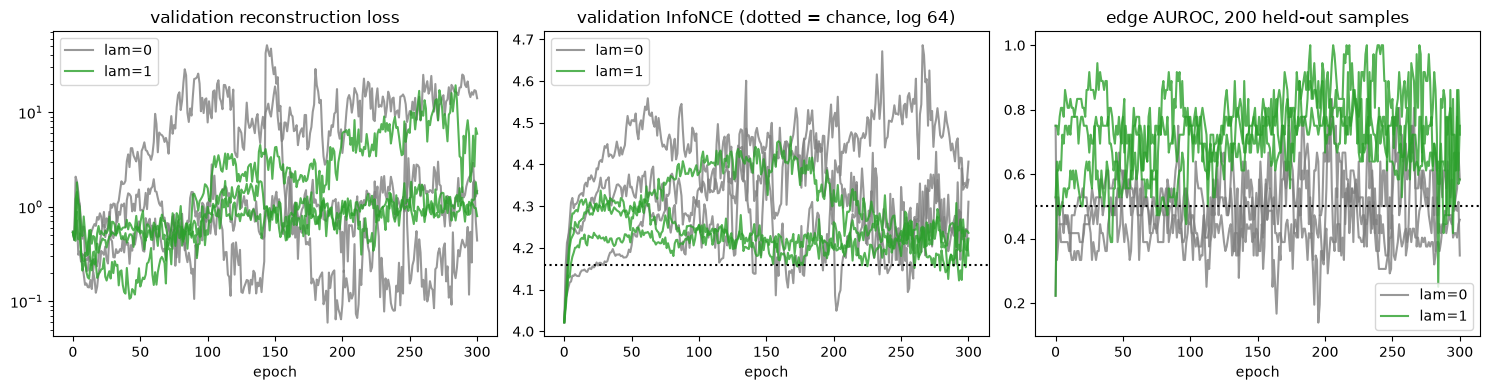

             auc  val_contrast  val_recon
lam epoch                                
0   0      0.500         4.022      0.535
    10     0.407         4.226      0.212
    25     0.463         4.294      0.535
    50     0.546         4.353      1.108
    100    0.472         4.346      3.223
    200    0.495         4.348      1.446
    300    0.463         4.360      5.316
1   0      0.500         4.022      0.535
    10     0.704         4.247      0.292
    25     0.741         4.269      0.353
    50     0.704         4.267      0.444
    100    0.759         4.296      1.023
    200    0.713         4.265      2.713
    300    0.685         4.213      2.700


In [8]:
t0 = time.time()
hist = pd.concat([fit_log(s, lam) for s in (0, 1, 2) for lam in (0, 1)], ignore_index=True)
print(f"{time.time()-t0:.0f}s")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for (lam, seed), g in hist.groupby(["lam", "seed"]):
    c = {0: "tab:gray", 1: "tab:green"}[lam]
    for a, col in zip(ax, ["val_recon", "val_contrast", "auc"]):
        a.plot(g.epoch, g[col], color=c, alpha=.8, label=f"lam={lam}" if seed == 0 else None)
ax[0].set_yscale("log"); ax[0].set_title("validation reconstruction loss")
ax[1].axhline(math.log(64), ls=":", color="k"); ax[1].set_title("validation InfoNCE (dotted = chance, log 64)")
ax[2].axhline(.5, ls=":", color="k"); ax[2].set_title("edge AUROC, 200 held-out samples")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

print(hist[hist.epoch.isin([0, 10, 25, 50, 100, 200, 300])].pivot_table(index=["lam", "epoch"], values=["val_recon", "val_contrast", "auc"]).round(3))

In [9]:
hist.to_csv("../derived/nb03_fit_log.csv", index=False)
d = gen_synthetic("local", num_views=6, corr=0.75, output_dim=100, num_samples=1000, seed=0)[0]
print("variance of the views (MSE of predicting the mean):", round(float(np.mean([x.var(0).mean() for x in d])), 3))
rows = []
for (lam, seed), g in hist.groupby(["lam", "seed"]):
    rows.append(dict(lam=lam, seed=seed, min_recon=g.val_recon.min(), at_epoch=int(g.epoch[g.val_recon.idxmin()]),
                     recon_at_300=g.val_recon.iloc[-1], auc_at_300=g.auc.iloc[-1], auc_best=g.auc.max(),
                     auc_mean_ep50_300=g.auc[g.epoch >= 50].mean(), contrast_min=g.val_contrast.min()))
display(pd.DataFrame(rows).round(3))

variance of the views (MSE of predicting the mean): 0.059


,lam,seed,min_recon,at_epoch,recon_at_300,auc_at_300,auc_best,auc_mean_ep50_300,contrast_min
0,0,0,0.204,201,1.465,0.347,0.778,0.495,4.021
1,0,1,0.059,189,0.439,0.583,0.833,0.519,4.023
2,0,2,0.123,17,14.043,0.458,0.667,0.445,4.022
3,1,0,0.173,12,5.920,0.583,0.944,0.742,4.021
4,1,1,0.106,42,0.795,0.722,1.000,0.751,4.023
5,1,2,0.264,8,1.386,0.750,0.917,0.709,4.022


201s


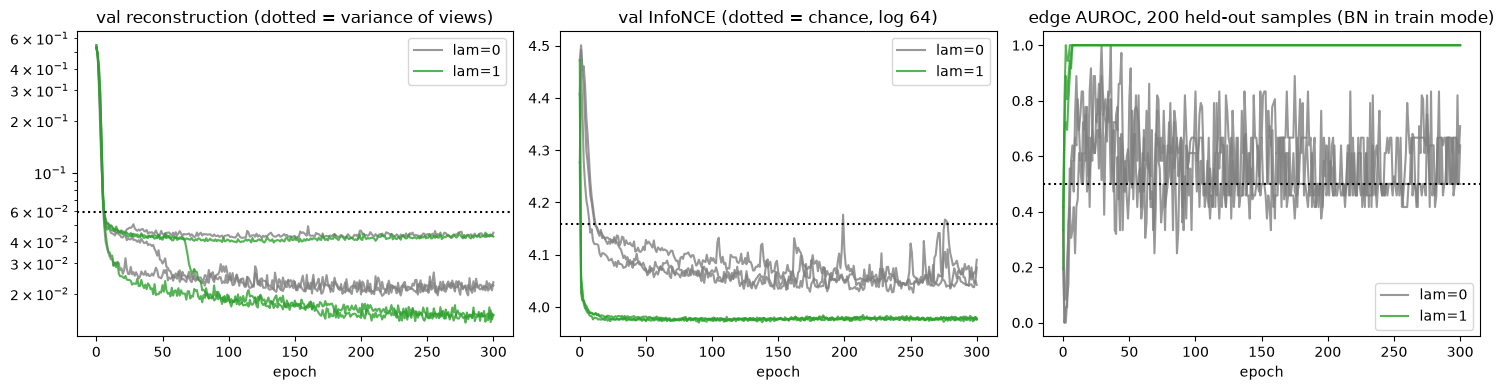

,lam,seed,min_recon,at_epoch,recon_at_300,contrast_at_300,auc_at_300,auc_mean_ep50_300
0,0,0,0.042,198,0.045,4.091,0.639,0.576
1,0,1,0.019,216,0.023,4.042,0.500,0.537
2,0,2,0.020,258,0.022,4.076,0.708,0.562
3,1,0,0.014,279,0.015,3.977,1.000,1.000
4,1,1,0.014,286,0.015,3.978,1.000,1.000
5,1,2,0.039,134,0.043,3.976,1.000,1.000


In [10]:
t0 = time.time()
hist2 = pd.concat([fit_log(s, lam, bn_train_eval=True) for s in (0, 1, 2) for lam in (0, 1)], ignore_index=True)
print(f"{time.time()-t0:.0f}s")
hist2.to_csv("../derived/nb03_fit_log_bn_train_eval.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for (lam, seed), g in hist2.groupby(["lam", "seed"]):
    c = {0: "tab:gray", 1: "tab:green"}[lam]
    for a, col in zip(ax, ["val_recon", "val_contrast", "auc"]):
        a.plot(g.epoch, g[col], color=c, alpha=.8, label=f"lam={lam}" if seed == 0 else None)
ax[0].set_yscale("log"); ax[0].axhline(0.059, ls=":", color="k"); ax[0].set_title("val reconstruction (dotted = variance of views)")
ax[1].axhline(math.log(64), ls=":", color="k"); ax[1].set_title("val InfoNCE (dotted = chance, log 64)")
ax[2].axhline(.5, ls=":", color="k"); ax[2].set_title("edge AUROC, 200 held-out samples (BN in train mode)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

rows = []
for (lam, seed), g in hist2.groupby(["lam", "seed"]):
    rows.append(dict(lam=lam, seed=seed, min_recon=g.val_recon.min(), at_epoch=int(g.epoch[g.val_recon.idxmin()]), recon_at_300=g.val_recon.iloc[-1],
                     contrast_at_300=g.val_contrast.iloc[-1], auc_at_300=g.auc.iloc[-1], auc_mean_ep50_300=g.auc[g.epoch >= 50].mean()))
display(pd.DataFrame(rows).round(3))